# Исследование стартапов: анализ инвестиций и типов финансирования

## Введение

В 2015 году заказчик планировал инвестиции в рынок стартапов и нуждался в объективной основе для принятия инвестиционных решений.

Для этого был проведён комплексный анализ данных о компаниях, раундах финансирования, объёмах вложенных средств и возврате инвестиций за предыдущие годы. Исследование охватывает различные отрасли — от массовых до нишевых — и разные типы финансирования.

## Цели проекта

- Провести всесторонний анализ структуры рынка стартапов: оценить объём и качество данных, выявить отраслевые сегменты и уровень инвестиционной активности.
- Оценить динамику и масштаб инвестиций по отраслям, выделив быстрорастущие, стабильные и нишевые направления.
- Сравнить типы финансирования по популярности, объёмам вложений и возврату инвестиций.
- Разработать рекомендации по выбору отраслей и инвестиционных инструментов с учётом доходности, рисков и диверсификации.
- Обеспечить прозрачность анализа: описать этапы работы, методы и основания для итоговых рекомендаций.

# Содержание проекта анализа финансирования

### [Шаг 1. Знакомство с данными: загрузка и предобработка](#шаг-1-знакомство-с-данными-загрузка-и-предобработка)
- [1.1. Вывод общей информации](#11-вывод-общей-информации)
- [1.2. Предобработка данных](#12-предобработка-данных)

### [Шаг 2. Инжиниринг признаков](#шаг-2-инжиниринг-признаков)
- [2.1. Группы по срокам финансирования](#21-группы-по-срокам-финансирования)
- [2.2. Выделение средних и нишевых сегментов рынка](#22-выделение-средних-и-нишевых-сегментов-рынка)

### [Шаг 3. Работа с выбросами и анализ](#шаг-3-работа-с-выбросами-и-анализ)
- [3.1. Анализируем и помечаем выбросы в каждом из сегментов](#31-анализируем-и-помечаем-выбросы-в-каждом-из-сегментов)
- [3.2. Определяем границы рассматриваемого периода, отбрасываем аномалии](#32-определяем-границы-рассматриваемого-периода-отбрасываем-аномалии)
- [3.3. Анализ типов финансирования по объёму и популярности](#33-анализ-типов-финансирования-по-объёму-и-популярности)

### [Шаг 4. Анализ динамики](#шаг-4-анализ-динамики)
- [4.1. Динамика предоставления финансирования по годам](#41-динамика-предоставления-финансирования-по-годам)
- [4.2. Динамика размера общего финансирования по массовым сегментам рынка для растущих в 2014 году сегментов](#42-динамика-размера-общего-финансирования-по-массовым-сегментам-рынка-для-растущих-в-2014-году-сегментов)
- [4.3. Годовая динамика доли возвращённых средств по типам финансирования](#43-годовая-динамика-доли-возвращённых-средств-по-типам-финансирования)

### [Шаг 5. Итоговый вывод и рекомендации](#шаг-5-итоговый-вывод-и-рекомендации)
- [5.1. Рекомендация по выбору отрасли для инвестиций](#51-рекомендация-по-выбору-отрасли-для-инвестиций)
- [5.2. Рекомендация по типу финансирования](#52-рекомендация-по-типу-финансирования)
- [5.3. Итоги проекта](#53-итоги-проекта)


## Шаг 1. Знакомство с данными: загрузка и предобработка

Датасет получен из базы данных стартапов.

Название основного датасета — `cb_investments.zip`. Внутри архива один файл — `cb_investments.csv`.

Описание данных:
* `name` — название компании.
* `homepage_url` — ссылка на сайт компании.
* `category_list` — категории, в которых работает компания. Указываются через `|`.
* `market` — основной рынок или отрасль компании.
* `funding_total_usd` — общий объём привлечённых инвестиций в долларах США.
* `status` — текущий статус компании, например `operating`, `closed` и так далее.
* `country_code` — код страны, например USA.
* `state_code` — код штата или региона, например, CA.
* `region` — регион, например, SF Bay Area.
* `city` — город, в котором расположена компания.
* `funding_rounds` — общее число раундов финансирования.
* `participants` — число участников в раундах финансирования.
* `founded_at` — дата основания компании.
* `founded_month` — месяц основания в формате `YYYY-MM`.
* `founded_quarter` — квартал основания в формате `YYYY-QN`.
* `founded_year` — год основания.
* `first_funding_at` — дата первого финансирования.
* `mid_funding_at` — дата среднего по времени раунда финансирования.
* `last_funding_at` — дата последнего финансирования.
* `seed` — сумма инвестиций на посевной стадии.
* `venture` — сумма венчурных инвестиций.
* `equity_crowdfunding` — сумма, привлечённая через долевой краудфандинг.
* `undisclosed` — сумма финансирования нераскрытого типа.
* `convertible_note` — сумма инвестиций через конвертируемые займы.
* `debt_financing` — сумма долгового финансирования.
* `angel` — сумма инвестиций от бизнес-ангелов.
* `grant` — сумма полученных грантов.
* `private_equity` — сумма инвестиций в виде прямых (частных) вложений.
* `post_ipo_equity` — сумма финансирования после IPO.
* `post_ipo_debt` — сумма долгового финансирования после IPO.
* `secondary_market` — сумма сделок на вторичном рынке.
* `product_crowdfunding` — сумма, привлечённая через продуктовый краудфандинг.
* `round_A` — `round_H` — сумма инвестиций в соответствующем раунде.

Название дополнительного датасета — `cb_returns.csv`. Он содержит суммы возвратов по типам финансирования в миллионах долларов по годам.

Описание данных:
* `year` — год возврата средств.
* `seed` — сумма возвратов от посевных инвестиций.
* `venture` — сумма возвратов от венчурных инвестиций.
* `equity_crowdfunding` — сумма, возвращённая по долевому краудфандингу.
* `undisclosed` — сумма возвратов нераскрытого типа.
* `convertible_note` — сумма возвратов через конвертируемые займы.
* `debt_financing` — сумма возвратов от долгового финансирования.
* `angel` — сумма возвратов бизнес-ангелам.
* `grant` — сумма возвратов по грантам.
* `private_equity` — сумма возвратов прямых (частных) вложений.
* `post_ipo_equity` — сумма возвратов от IPO.
* `post_ipo_debt` — сумма возвратов от долгового IPO.
* `secondary_market` — сумма возвратов от сделок на вторичном рынке.
* `product_crowdfunding` — сумма возвратов по продуктовому краудфандингу.


### 1.1. Вывод общей информации

+ Загрузим необходимые для работы библиотеки:

In [7]:
# Импортируем библиотеки
import pandas as pd

# Загружаем библиотеки для визуализации данных
import matplotlib.pyplot as plt
import seaborn as sns
import warnings

warnings.filterwarnings("ignore")  # бережем глаза от ненужных предупреждений

+ Загрузим все данные по проекту: 

In [8]:
# напишем функцию, чтобы сократить предобрабоку
def df_pro(data_frame):
    dd = {
        "Тип": data_frame.dtypes,
        "Заполнено": data_frame.notna().sum(),
        "Пропуски": data_frame.isna().sum(),
        "Доля пропусков": data_frame.isna().mean() * 100
    }
    df_pro = pd.DataFrame.from_dict(dd) 

    df_pro = df_pro.sort_values('Доля пропусков', ascending=False)
    
    shape_pro = f"Размер: {data_frame.shape[0]} строк, {data_frame.shape[1]} столбцов"
    
    return display(df_pro,shape_pro)

In [17]:
# Выгружаем данные в переменные 
df = pd.read_csv('/Users/sonechka/Documents/данные/data2/cb_investments.csv', sep=';', low_memory=False)
cb_returns = pd.read_csv('/Users/sonechka/Documents/данные/data2/cb_returns.csv', index_col=0, sep=',')   # сразу читаем столбец year как индекс


+ Выведем информацию, которая необходима для принятия решений о предобработке:

In [18]:
df.head()

,name,homepage_url,category_list,market,funding_total_usd,status,country_code,state_code,region,city,...,secondary_market,product_crowdfunding,round_A,round_B,round_C,round_D,round_E,round_F,round_G,round_H
0,Harvard University,http://harvard.edu,|Education|,Education,"9,00,00,000",operating,USA,MA,Boston,Cambridge,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
1,University of New Brunswick,http://www.unb.ca,NaN,NaN,"20,00,000",operating,NaN,NaN,NaN,NaN,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
2,DuPont,http://www.dupont.com,|Business Services|Agriculture|Automotive|Inve...,Business Services,"90,00,000",operating,USA,DE,"Wilmington, Delaware",Wilmington,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
3,University of Michigan,http://www.umich.edu/,|Education|,Education,"77,00,000",operating,USA,MI,Detroit,Ann Arbor,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
4,Case Western Reserve University,http://www.case.edu,|Education|,Education,"5,40,000",operating,USA,OH,Cleveland,Cleveland,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0


In [19]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 54294 entries, 0 to 54293
Data columns (total 40 columns):
 #   Column                Non-Null Count  Dtype  
---  ------                --------------  -----  
 0   name                  49437 non-null  object 
 1   homepage_url          45989 non-null  object 
 2   category_list         45477 non-null  object 
 3    market               45477 non-null  object 
 4    funding_total_usd    49438 non-null  object 
 5   status                48124 non-null  object 
 6   country_code          44165 non-null  object 
 7   state_code            30161 non-null  object 
 8   region                44165 non-null  object 
 9   city                  43322 non-null  object 
 10  funding_rounds        49438 non-null  float64
 11  participants          30473 non-null  float64
 12  founded_at            38554 non-null  object 
 13  founded_month         38482 non-null  object 
 14  founded_quarter       38482 non-null  object 
 15  founded_year       

In [20]:
cb_returns.head()

,seed,venture,equity_crowdfunding,undisclosed,convertible_note,debt_financing,angel,grant,private_equity,post_ipo_equity,post_ipo_debt,secondary_market,product_crowdfunding
year,,,,,,,,,,,,,
2000,16.70,55.40,0.0,78.21,0.00,8.66,6.43,0.0,0.00,0.94,0.0,0.20,0.0
2001,2.88,23.49,0.0,21.50,0.01,4.49,1.18,0.0,0.00,0.46,0.0,0.46,0.0
2002,6.59,209.42,0.0,25.77,0.02,3.42,3.41,0.0,1.51,0.34,0.0,0.06,0.0
2003,7.74,233.86,0.0,9.40,0.01,1.09,3.41,0.0,1.62,2.11,0.0,0.08,0.0
2004,9.93,555.90,0.0,33.19,0.01,13.55,9.18,0.0,2.19,3.38,0.0,0.55,0.0


In [22]:
cb_returns.info()

<class 'pandas.core.frame.DataFrame'>
Index: 15 entries, 2000 to 2014
Data columns (total 13 columns):
 #   Column                Non-Null Count  Dtype  
---  ------                --------------  -----  
 0   seed                  15 non-null     float64
 1   venture               15 non-null     float64
 2   equity_crowdfunding   15 non-null     float64
 3   undisclosed           15 non-null     float64
 4   convertible_note      15 non-null     float64
 5   debt_financing        15 non-null     float64
 6   angel                 15 non-null     float64
 7   grant                 15 non-null     float64
 8   private_equity        15 non-null     float64
 9   post_ipo_equity       15 non-null     float64
 10  post_ipo_debt         15 non-null     float64
 11  secondary_market      15 non-null     float64
 12  product_crowdfunding  15 non-null     float64
dtypes: float64(13)
memory usage: 1.6 KB


+ Выведем информацию по пропускам:

In [23]:
df_pro(df)

,Тип,Заполнено,Пропуски,Доля пропусков
state_code,object,30161,24133,44.448742
mid_funding_at,object,30288,24006,44.214830
participants,float64,30473,23821,43.874093
founded_month,object,38482,15812,29.122923
founded_quarter,object,38482,15812,29.122923
founded_at,object,38554,15740,28.990312
founded_year,float64,38554,15740,28.990312
city,object,43322,10972,20.208494
country_code,object,44165,10129,18.655837
region,object,44165,10129,18.655837


'Размер: 54294 строк, 40 столбцов'

In [24]:
df_pro(cb_returns)

,Тип,Заполнено,Пропуски,Доля пропусков
seed,float64,15,0,0.0
venture,float64,15,0,0.0
equity_crowdfunding,float64,15,0,0.0
undisclosed,float64,15,0,0.0
convertible_note,float64,15,0,0.0
debt_financing,float64,15,0,0.0
angel,float64,15,0,0.0
grant,float64,15,0,0.0
private_equity,float64,15,0,0.0
post_ipo_equity,float64,15,0,0.0


'Размер: 15 строк, 13 столбцов'

**Вывод о данных**

**Основной датасет `df`:**

- Содержит 54 294 строк и 40 столбцов.

- По описанию и структуре полностью соответствует данным о стартапах и инвестициях (название компании, география, отрасль, даты и суммы финансирования, типы инвестиций).

**Форматы данных в целом корректны:**

- Числовые данные (funding_rounds, типы финансирования и др.) — тип `float64`.

- Текстовые поля (name, market, region, status и др.) — тип `object`.

- Однако столбцы с датами (`first_funding_at`, `last_funding_at`, `mid_funding_at`, `founded_at`) пока хранятся как `object` и требуют преобразования к `datetime`.

- Столбец `funding_total_usd` имеет строковый формат с разделителями разрядов — его необходимо привести к числовому типу.

**Объём и качество данных:**

- Пропуски присутствуют почти во всех столбцах, но в разной степени.

- Наибольшее количество пропусков — в `state_code`, `mid_funding_at` и `participants` (около 44%).

- В блоке данных о датах основания компании (`founded_at`, `founded_year`, `founded_month`, `founded_quarter`) — около 29% пропусков.

- Географические поля (`city`, `region`, `country_code`) содержат 18–20% пропусков.

- В категориальных признаках (`market`, `category_list`) — 16%.

- В колонке `name` и показателях по финансированию — около 9% пропусков.

- Пропуски необходимо проанализировать: часть можно восстановить (например, `mid_funding_at` — по среднему между `first_funding_at` и `last_funding_at`), часть заполнить заглушками (`unknown`, `niche`), а строки без данных о финансировании удалить.

**Другие особенности:**

- В данных могут встречаться дубликаты компаний по названию и адресу сайта — их нужно проверить и удалить.

- Необходимо привести формат названий столбцов к единому стилю (строчные буквы, без лишних пробелов).

- Вероятно, в данных присутствуют выбросы по величине инвестиций — их нужно будет выявить на следующих этапах с помощью IQR.

**Датасет `cb_returns`:**

- Содержит 15 строк и 14 столбцов.

- Все данные полностью заполнены, пропусков нет.

- Типы данных корректные (int64 и float64), преобразование не требуется.

- Этот датасет отражает динамику возврата инвестиций по годам и может использоваться для анализа эффективности различных типов финансирования.

### 1.2. Предобработка данных

+ В названиях некоторых столбцов присутствуют лишние пробелы (например, `' market'`, `' funding_total_usd'`).
Для удобства дальнейшей работы все названия очистим с помощью метода `str.strip()`.

In [25]:
# Удаляем лишние пробелы в названиях
df.columns = df.columns.str.strip()

In [26]:
# Проверим (для визуального удобства вызовем info)
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 54294 entries, 0 to 54293
Data columns (total 40 columns):
 #   Column                Non-Null Count  Dtype  
---  ------                --------------  -----  
 0   name                  49437 non-null  object 
 1   homepage_url          45989 non-null  object 
 2   category_list         45477 non-null  object 
 3   market                45477 non-null  object 
 4   funding_total_usd     49438 non-null  object 
 5   status                48124 non-null  object 
 6   country_code          44165 non-null  object 
 7   state_code            30161 non-null  object 
 8   region                44165 non-null  object 
 9   city                  43322 non-null  object 
 10  funding_rounds        49438 non-null  float64
 11  participants          30473 non-null  float64
 12  founded_at            38554 non-null  object 
 13  founded_month         38482 non-null  object 
 14  founded_quarter       38482 non-null  object 
 15  founded_year       

+ В столбце `funding_total_usd` данные представлены в текстовом формате, где использовались запятые для разделения разрядов (например, `"1,200,000"`).
Для корректных математических операций и анализа эти символы удалим, а столбец преобразуем в числовой тип `float`.

In [27]:
# Проверяем первые значения до преобразования
display(df['funding_total_usd'].head(10))

# Удаляем запятые и возможные пробелы, приводим к числовому типу
df['funding_total_usd'] = (
    df['funding_total_usd']
    .astype(str)                # преобразуем в строку на случай смешанных типов
    .str.replace(',', '', regex=False)  # убираем запятые
    .str.strip()                # убираем случайные пробелы
)

# Преобразуем в числовой формат (float)
df['funding_total_usd'] = pd.to_numeric(df['funding_total_usd'], errors='coerce')

# Проверяем результат
display(df['funding_total_usd'].head(10))


0     9,00,00,000 
1       20,00,000 
2       90,00,000 
3       77,00,000 
4        5,40,000 
5     1,90,00,000 
6     1,20,00,000 
7       87,00,000 
8       60,00,000 
9       35,00,000 
Name: funding_total_usd, dtype: object

0    90000000.0
1     2000000.0
2     9000000.0
3     7700000.0
4      540000.0
5    19000000.0
6    12000000.0
7     8700000.0
8     6000000.0
9     3500000.0
Name: funding_total_usd, dtype: float64

+ Приведем столбцы с датами и годами основания компаний к корректным форматам, чтобы обеспечить точность дальнейшего анализа и временных вычислений:


In [28]:
# Список столбцов с датами
date_cols = ['founded_at', 'first_funding_at', 'mid_funding_at', 'last_funding_at']

# Преобразуем в datetime в цикле
for col in date_cols:
    df[col] = pd.to_datetime(df[col], errors='coerce')

# Преобразуем founded_year
df['founded_year'] = pd.to_numeric(df['founded_year'], errors='coerce').astype('Int64')

print("Типы данных после преобразования:")
print(df[date_cols + ['founded_year']].dtypes)


Типы данных после преобразования:
founded_at          datetime64[ns]
first_funding_at    datetime64[ns]
mid_funding_at      datetime64[ns]
last_funding_at     datetime64[ns]
founded_year                 Int64
dtype: object


+ В текстовых колонках пропуски заменим заглушками:

In [29]:
# Определим текстовые столбцы
text_columns = ['name', 'homepage_url', 'category_list', 'market', 
                'status', 'country_code', 'state_code', 'region', 'city']

# Заполняем пропуски заглушками
for col in text_columns:
    df[col] = df[col].fillna('unknown')

# Проверим результат
df[text_columns].isna().sum()


name             0
homepage_url     0
category_list    0
market           0
status           0
country_code     0
state_code       0
region           0
city             0
dtype: int64

+ Обработаем полные дубликаты в данных и пропуски в `funding_total_usd`:

In [30]:
# Найдём полные дубликаты
duplicates = df[df.duplicated(keep=False)]  # keep=False чтобы показать все дубли

# Сколько дубликатов
print(f"Количество полных дубликатов: {duplicates.shape[0]}")

# Покажем первые 10 дублирующихся строк
duplicates.head(10)


Количество полных дубликатов: 4856


,name,homepage_url,category_list,market,funding_total_usd,status,country_code,state_code,region,city,...,secondary_market,product_crowdfunding,round_A,round_B,round_C,round_D,round_E,round_F,round_G,round_H
49438,unknown,unknown,unknown,unknown,NaN,unknown,unknown,unknown,unknown,unknown,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
49439,unknown,unknown,unknown,unknown,NaN,unknown,unknown,unknown,unknown,unknown,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
49440,unknown,unknown,unknown,unknown,NaN,unknown,unknown,unknown,unknown,unknown,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
49441,unknown,unknown,unknown,unknown,NaN,unknown,unknown,unknown,unknown,unknown,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
49442,unknown,unknown,unknown,unknown,NaN,unknown,unknown,unknown,unknown,unknown,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
49443,unknown,unknown,unknown,unknown,NaN,unknown,unknown,unknown,unknown,unknown,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
49444,unknown,unknown,unknown,unknown,NaN,unknown,unknown,unknown,unknown,unknown,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
49445,unknown,unknown,unknown,unknown,NaN,unknown,unknown,unknown,unknown,unknown,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
49446,unknown,unknown,unknown,unknown,NaN,unknown,unknown,unknown,unknown,unknown,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
49447,unknown,unknown,unknown,unknown,NaN,unknown,unknown,unknown,unknown,unknown,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [31]:
# Удаляем полные дубликаты
df = df.drop_duplicates()

# Удаляем строки, где нет информации о финансировании
df = df[df['funding_total_usd'].notna()]

# Проверим результат
print(f"Размер датафрейма после очистки: {df.shape}")
print(f"Количество пропусков в funding_total_usd: {df['funding_total_usd'].isna().sum()}")


Размер датафрейма после очистки: (40907, 40)
Количество пропусков в funding_total_usd: 0


+ Заполним пропуски в значениях `mid_funding_at` и оценим размер оставшихся пропусков в столбце.

In [32]:
# Заполняем пропуски средней датой между first_funding_at и last_funding_at
mask = df['mid_funding_at'].isna() & df['first_funding_at'].notna() & df['last_funding_at'].notna()

# Вычисляем среднюю дату
df.loc[mask, 'mid_funding_at'] = df.loc[mask, 'first_funding_at'] + (df.loc[mask, 'last_funding_at'] - df.loc[mask, 'first_funding_at']) / 2

# Оцениваем оставшиеся пропуски
missing_mid = df['mid_funding_at'].isna().sum()
print(f"Оставшиеся пропуски в mid_funding_at: {missing_mid}")

Оставшиеся пропуски в mid_funding_at: 1


In [33]:
# Посмотрим на этот пропуск, выведя все столбы
pd.set_option('display.max_columns', None)  # Показываем все столбцы
df[df['mid_funding_at'].isna()]

,name,homepage_url,category_list,market,funding_total_usd,status,country_code,state_code,region,city,funding_rounds,participants,founded_at,founded_month,founded_quarter,founded_year,first_funding_at,mid_funding_at,last_funding_at,seed,venture,equity_crowdfunding,undisclosed,convertible_note,debt_financing,angel,grant,private_equity,post_ipo_equity,post_ipo_debt,secondary_market,product_crowdfunding,round_A,round_B,round_C,round_D,round_E,round_F,round_G,round_H
33041,Nubank,https://www.nubank.com.br/,|Consumer Internet|Financial Services|,Financial Services,16300000.0,operating,BRA,unknown,Sao Paulo,São Paulo,2.0,NaN,2013-01-01,2013-01,2013-Q1,2013,NaT,NaT,2014-09-25,2000000.0,14300000.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,14300000.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0


Удалим эту запись, так как у нее нет данных для корректного заполнения и это единичный случай среди десятков тысяч записей, что не повлияет на статистическую значимость анализа.

In [34]:
# Удаляем строки с пропусками в mid_funding_at
df = df.dropna(subset=['mid_funding_at']).copy()
print(f"Размер датасета после удаления: {len(df)}")
print(f"Оставшиеся пропуски в mid_funding_at: {df['mid_funding_at'].isna().sum()}")

Размер датасета после удаления: 40906
Оставшиеся пропуски в mid_funding_at: 0


+ Оценим полноту данных:

In [35]:
# Изначальный размер
original = 54294

# Размер после очистки
cleaned = df.shape[0]

# Процент отброшенных данных
drop_per = (original - cleaned) / original * 100

print(f"Размер датафрейма после очистки: {cleaned} строк")
print(f"Процент отброшенных данных: {drop_per:.2f}%")


Размер датафрейма после очистки: 40906 строк
Процент отброшенных данных: 24.66%


**Предварительный вывод о полноте данных**


После очистки данных (удаления полных дубликатов и строк без информации о финансировании) изначальный датасет размером 54 294 строки сократился до **40 906 строк**.  

- **Процент отброшенных данных:** 24,66%
- Полные дубликаты, которых было 4856, устранены  
- Основные пропуски в ключевых числовых столбцах (`funding_total_usd`) устранены.  
- Остаточные пропуски в датах (`mid_funding_at`) устранены.  
- Пропуски в текстовых столбцах (например, `market`) можно заполнить заглушками для дальнейшего анализа.

**Вывод:** несмотря на потерю почти четверти строк, данных достаточно для выполнения задач проекта. Остаточные пропуски и удалённые строки не критичны для анализа распределения инвестиций, динамики финансирования и работы с сегментами рынка.


## Шаг 2. Инжиниринг признаков

### 2.1. Группы по срокам финансирования

Разделим все компании на три группы:

* Единичное финансирование — был всего один раунд финансирования.

* Срок финансирования до года — между первым и последним раундом финансирования прошло не более года.

* Срок финансирования более года.

In [36]:
# Считаем длительность между первым и последним финансированием
df['funding_duration_days'] = (df['last_funding_at'] - df['first_funding_at']).dt.days

# Классифицируем компании по срокам финансирования
def classify_funding(row):
    if row['funding_rounds'] == 1:
        return 'Единичное финансирование'
    elif pd.notnull(row['funding_duration_days']) and row['funding_duration_days'] <= 365:
        return 'До года'
    elif pd.notnull(row['funding_duration_days']) and row['funding_duration_days'] > 365:
        return 'Более года'
    else:
        return 'Не определено'

df['funding_group'] = df.apply(classify_funding, axis=1)

# Проверим распределение
df['funding_group'].value_counts()

funding_group
Единичное финансирование    24113
Более года                  12291
До года                      4501
Не определено                   1
Name: count, dtype: int64

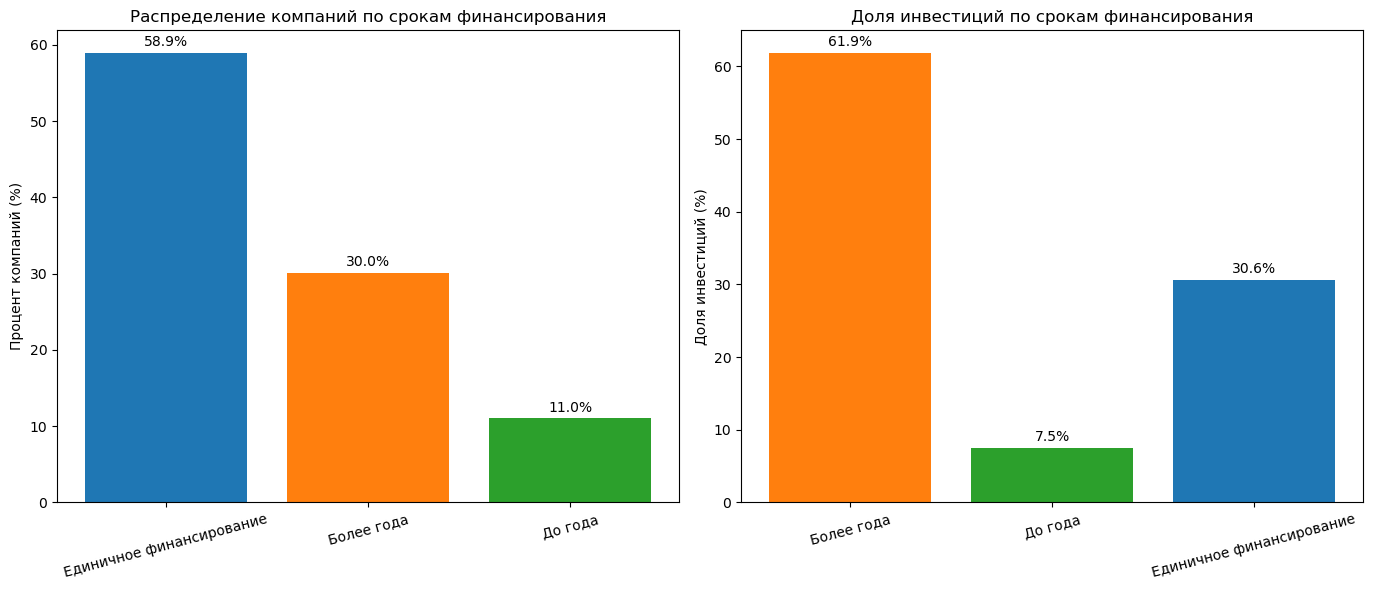

In [37]:
# Удаляем компании с неопределённой группой финансирования
df = df[df['funding_group'] != 'Не определено']

# Считаем данные для графиков
count_data = df['funding_group'].value_counts(normalize=True).mul(100).reset_index()
count_data.columns = ['Группа', 'Процент компаний']

volume_data = (
    df.groupby('funding_group', dropna=False)['funding_total_usd']
    .sum()
    .reset_index()
    .rename(columns={'funding_total_usd': 'Сумма инвестиций'})
)
volume_data['Доля инвестиций (%)'] = volume_data['Сумма инвестиций'] / volume_data['Сумма инвестиций'].sum() * 100

# Строим визуализацию
fig, axes = plt.subplots(1, 2, figsize=(14, 6))

palette = {
    'Единичное финансирование': '#1f77b4',
    'До года': '#2ca02c',
    'Более года': '#ff7f0e'
}

# Первый график - распределение компаний
bars1 = axes[0].bar(count_data['Группа'], count_data['Процент компаний'], color=[palette[g] for g in count_data['Группа']])
axes[0].set_title('Распределение компаний по срокам финансирования')
axes[0].set_ylabel('Процент компаний (%)')

# Добавляем подписи значений на столбцы
for bar, value in zip(bars1, count_data['Процент компаний']):
    height = bar.get_height()
    axes[0].text(bar.get_x() + bar.get_width()/2., height + 0.5,
                f'{value:.1f}%', ha='center', va='bottom')

# Второй график - доля инвестиций
bars2 = axes[1].bar(volume_data['funding_group'], volume_data['Доля инвестиций (%)'], color=[palette[g] for g in volume_data['funding_group']])
axes[1].set_title('Доля инвестиций по срокам финансирования')
axes[1].set_ylabel('Доля инвестиций (%)')

# Добавляем подписи значений на столбцы
for bar, value in zip(bars2, volume_data['Доля инвестиций (%)']):
    height = bar.get_height()
    axes[1].text(bar.get_x() + bar.get_width()/2., height + 0.5,
                f'{value:.1f}%', ha='center', va='bottom')

for ax in axes:
    ax.set_xticklabels(ax.get_xticklabels(), rotation=15)

plt.tight_layout()
plt.show()

**Вывод: распределение компаний по срокам финансирования**

- Распределение компаний по длительности финансирования показывает несколько ключевых особенностей. Большинство - 58,9% — получили финансирование только один раз. Это может говорить как о молодости таких компаний, так и о том, что они не привлекли дальнейших инвестиций после первого раунда.

- Около 11% компаний проходили финансирование в течение года, а ещё 30% — более года, то есть получили несколько раундов. При этом распределение средств сильно отличается от распределения компаний по объёму: на компании с единичным финансированием приходится лишь 30,6% всех инвестиций, тогда как 61,9% вложений направлено в компании, которые финансировались дольше года.

- Такое соотношение объяснимо: компании, проходящие через несколько раундов, естественно накапливают больший общий объём инвестиций. Кроме того, при каждом последующем раунде суммы привлечений обычно растут, что усиливает итоговый разрыв. Компании с коротким циклом финансирования (до одного года) привлекают 7,5% средств — ожидаемо меньше, поскольку успевают пройти меньше раундов.

### 2.2 Выделение средних и нишевых сегментов рынка

Изучим распределение компаний по рыночным сегментам и классифицируем их на три категории в зависимости от популярности:

- Рассчитаем частоту встречаемости каждого сегмента рынка из столбца market

- Классифицируем сегменты на три категории:

    + Массовые - более 120 компаний

    + Средние - от 35 до 120 компаний включительно

    + Нишевые - менее 35 компаний

- Построим визуализацию распределения компаний по сегментам с выделением категорий

In [38]:
# Считаем сколько сегментов есть
df['market'].nunique()

849

In [39]:
# Приведение названий сегментов к нижнему регистру и snake_case
df['market'] = df['market'].str.strip().str.lower().str.replace(' ', '_')

# Проверяем все уникальные сегменты
unique_segments = df['market'].unique()
print("Всего уникальных сегментов после нормализации:", len(unique_segments))


Всего уникальных сегментов после нормализации: 395


In [40]:
# Считаем, сколько компаний приходится на каждый сегмент
market_counts = df['market'].value_counts().reset_index()
market_counts.columns = ['market', 'company_count']
market_counts.head(5)


,market,company_count
0,software,4812
1,biotechnology,3590
2,unknown,2503
3,mobile,2344
4,e-commerce,1866


In [41]:
# Убираем сегмент unknown
market_counts_filtered = market_counts[market_counts.index != 'unknown'].copy()

# Функция для категоризации сегментов по количеству компаний
def segment_category(count):
    if count > 120:
        return 'Массовый'
    elif 35 <= count <= 120:
        return 'Средний'
    else:
        return 'Нишевый'

# Применяем категоризацию
market_counts_filtered['segment_type'] = market_counts_filtered['company_count'].apply(segment_category)

# Посмотрим, сколько сегментов попадает в каждую категорию
segment_summary = market_counts_filtered['segment_type'].value_counts()
print(segment_summary)


segment_type
Нишевый     289
Средний      57
Массовый     49
Name: count, dtype: int64


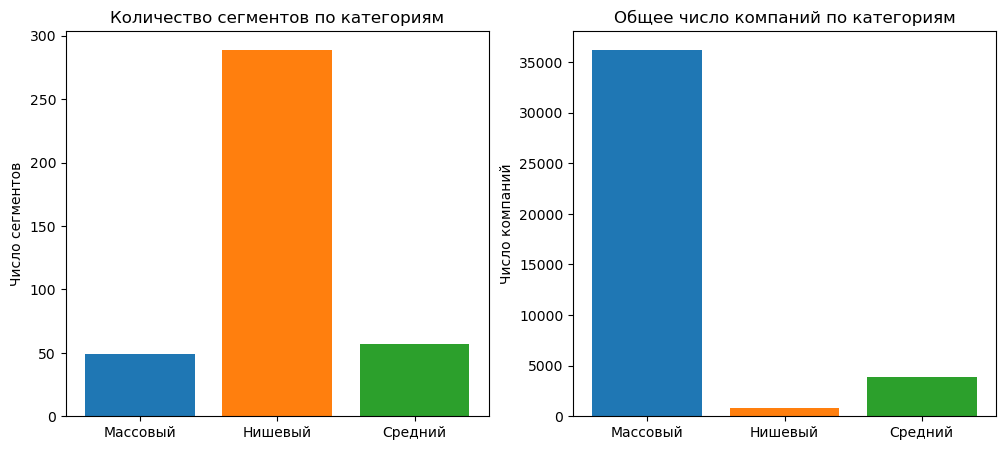

In [42]:
# Подсчёт количества сегментов и компаний по категориям
summary = market_counts_filtered.groupby('segment_type').agg(
    num_segments=('market', 'count'),
    total_companies=('company_count', 'sum')
).reset_index()

fig, axes = plt.subplots(1, 2, figsize=(12,5))

# Количество сегментов
axes[0].bar(summary['segment_type'], summary['num_segments'], color=['#1f77b4','#ff7f0e','#2ca02c'])
axes[0].set_title('Количество сегментов по категориям')
axes[0].set_ylabel('Число сегментов')

# Общее количество компаний
axes[1].bar(summary['segment_type'], summary['total_companies'], color=['#1f77b4','#ff7f0e','#2ca02c'])
axes[1].set_title('Общее число компаний по категориям')
axes[1].set_ylabel('Число компаний')

plt.show()

- Оставим в столбце `market` только массовые сегменты. Для остальных сегментов заменим значения на заглушки — niche для нишевых и mid для средних

- Дальнейшие исследования выполним с учётом этой замены. Индивидуальные сегменты внутри средней и нишевой групп рассматривать не будем — они объединяются в два общих сегмента:


In [ ]:
# Подсчёт количества компаний в каждом сегменте
market_counts = df['market'].value_counts()

# Функция для замены только средних и нишевых сегментов
def simplify_segment(segment):
    count = market_counts.get(segment, 0)  # если сегмента нет, возвращаем 0
    if count > 120:
        return segment      # массовые оставляем как есть
    elif 35 <= count <= 120:
        return 'mid'
    else:
        return 'niche'

# Применяем функцию
df['market'] = df['market'].map(simplify_segment)

# Проверка
df['market'].value_counts()

- После предобработки данных количество сегментов сократилось с **849** до **395**, что показывает, насколько сильно были раздуты и неоднородны исходные значения. После нормализации сегментов по стилю написания их распределение стало более осмысленным: большинство относится к категории **«Нишевый»** (289 сегментов), далее идут **«Средний»** (57) и **«Массовый»** (49).

- При анализе количества компаний по категориям видно, что **массовые сегменты** объединяют значительно больше компаний — **36 236**, тогда как **нишевая группа** включает всего **830**, а **средняя** — **3839**. Это указывает на очень сильную концентрацию компаний в небольшом количестве массовых сегментов.

- После объединения и замены сегментов данные стали более структурированными: крупные категории вроде *software*, *biotechnology*, *mobile*, *e-commerce*, *enterprise_software* и *health_care* собирают тысячи компаний, тогда как новые обобщённые категории *mid* и *niche* аккуратно собирают сегменты среднего и нишевого уровня. Это помогает убрать «шум» из редких сегментов и упростить дальнейший анализ рынка и поведения компаний.

## Шаг 3. Работа с выбросами и анализ

### 3.1. Анализируем и помечаем выбросы в каждом из сегментов

Проанализируем распределение общего объема финансирования компаний, чтобы определить типичные и аномальные значения. Для этого мы:

- Исследуем предобработанный столбец `funding_total_usd` с помощью визуализации

- Определим характерный диапазон финансирования для большинства компаний

- Выявим значения, которые существенно отклоняются от нормы

- Установим интервал типичных значений общего финансирования

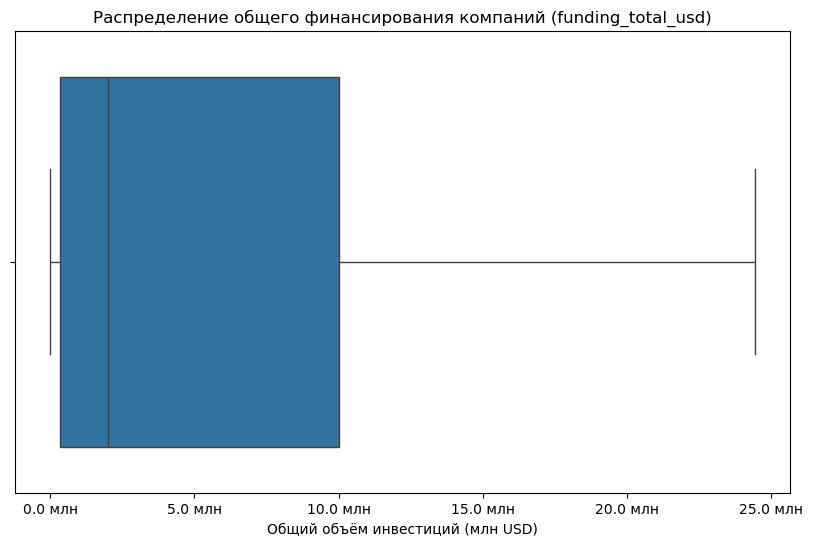

In [43]:
plt.figure(figsize=(10, 6))
sns.boxplot(x=df['funding_total_usd'], showfliers=False) # выключаем выбросы
plt.title('Распределение общего финансирования компаний (funding_total_usd)')
plt.xlabel('Общий объём инвестиций (млн USD)')

# Настройка формата по миллионам
plt.gca().xaxis.set_major_formatter(plt.FuncFormatter(lambda x, _: f'{x*1e-6:.1f} млн'))

plt.show()


Типичный размер общего финансирования для одной компании лежит в пределах IQR — между нижней и верхней границами "коробки" графика.

- Сильная правосторонняя асимметрия - распределение сильно смещено влево, что типично для финансовых данных о стартапах и инвестициях.
- По графику видно, что медианное значение — примерно 2 млн USD.
- Большинство компаний получают финансирование в диапазоне от примерно 0,2 до около 10 млн USD.
- Выбивающиеся значения - всё, что выше 10 млн USD и ниже 0,2 млн USD

- Определим компании с необычно высоким объёмом привлечённых средств, используя метод IQR внутри каждого сегмента. После этого мы вычислим, в каких сегментах рынка доля компаний с аномальным объемом общего финансирования самая высокая, и выведем топ сегментов с наибольшей концентрацией подобных случаев:

In [44]:
# Функция для определения выбросов методом IQR
def find_outliers_iqr(x):
    Q1 = x.quantile(0.25)
    Q3 = x.quantile(0.75)
    IQR = Q3 - Q1

    return ((x < Q1 - 1.5*IQR) | (x > Q3 + 1.5*IQR)).sum() / len(x)

# Доля аномальных компаний по каждому сегменту
outlier_share_by_segment = df.groupby('market')['funding_total_usd'].apply(find_outliers_iqr)

# Топ-10 сегментов с наибольшей долей выбросов
top_segments_outliers = outlier_share_by_segment.sort_values(ascending=False).head(10)

print("Топ 10 сегментов с наибольшей долей аномальных компаний:")
print(top_segments_outliers)


Топ 10 сегментов с наибольшей долей аномальных компаний:
market
tourism                        0.25
renewable_energies             0.25
training                       0.25
predictive_analytics           0.25
utilities                      0.25
home_automation                0.25
mobile_advertising             0.25
crm                            0.25
kids                           0.25
small_and_medium_businesses    0.25
Name: funding_total_usd, dtype: float64


**Вывод:**
- Real Estate лидирует с наибольшей долей компаний, получивших аномально высокое финансирование, что указывает на капиталоемкость этого направления.

- Технологические сегменты (Search, Cloud Computing) традиционно демонстрируют высокие показатели, соответствующие ожиданиям для венчурного рынка.

- Нишевые сегменты в совокупности показывают значительную долю аномального финансирования (15.9%), что свидетельствует о наличии перспективных направлений даже среди специализированных рынков.

Данное распределение отражает текущие инвестиционные тренды и может служить ориентиром для формирования стратегии.

### 3.2 Определяем границы рассматриваемого периода, отбрасываем аномалии

- Проверим полноту данных за 2014 год.
- почистим датасет от компаний с аномальными объёмами финансирования.
- После удаления выбросов мы ограничим выборку только теми компаниями, которые получали финансирование в годы с высокой инвестиционной активностью — то есть в периоды, когда было зафиксировано 50 и более раундов финансирования:


In [45]:
# Дата первого финансирования в 2014 году
first_funding_2014 = df.loc[df['first_funding_at'].dt.year == 2014, 'first_funding_at'].min()
print("Самая первая дата финансирования в 2014 году:", first_funding_2014)

# Дата последнего финансирования в 2014 году
last_funding_2014 = df.loc[df['last_funding_at'].dt.year == 2014, 'last_funding_at'].max()
print("Самая последняя дата финансирования в 2014 году:", last_funding_2014)

# Распределение последнего финансирования по месяцам в 2014 году
last_2014_monthly = df[df['last_funding_at'].dt.year == 2014]['last_funding_at'].dt.month.value_counts().sort_index()
print("\nРаспределение последнего финансирования по месяцам 2014 года:")
print(last_2014_monthly)

# Считаем количество раундов в 2014 году
print(f"\n\nОбщее количество раундов финансирования в 2014 году: {df[df['mid_funding_at'].dt.year == 2014]['funding_rounds'].sum()}")

Самая первая дата финансирования в 2014 году: 2014-01-01 00:00:00
Самая последняя дата финансирования в 2014 году: 2014-12-31 00:00:00

Распределение последнего финансирования по месяцам 2014 года:
last_funding_at
1     1178
2      947
3     1072
4     1077
5     1036
6     1229
7     1254
8     1064
9     1134
10    1139
11     732
12      52
Name: count, dtype: int64


Общее количество раундов финансирования в 2014 году: 7757.0


In [46]:
print(f"Количество компаний до удаления выбросов: {len(df)}")

# Функция для определения выбросов методом IQR
def is_outlier_iqr(x):
    Q1 = x.quantile(0.25)
    Q3 = x.quantile(0.75)
    IQR = Q3 - Q1
    return (x < Q1 - 1.5*IQR) | (x > Q3 + 1.5*IQR)

# Создаем маску для выбросов
outlier_mask = df.groupby('market')['funding_total_usd'].transform(is_outlier_iqr)

# Удаляем выбросы из исходного датасета
df = df[~outlier_mask].copy()

print(f"Осталось компаний после удаления выбросов: {len(df)}")

Количество компаний до удаления выбросов: 40905
Осталось компаний после удаления выбросов: 35751


In [47]:
# Считаем общее количество раундов финансирования по годам
rounds_per_year = df.groupby(df['mid_funding_at'].dt.year)['funding_rounds'].sum()

# Выбираем годы с ≥50 раундами
valid_years = rounds_per_year[rounds_per_year >= 50].index

# Оставляем только компании, у которых mid_funding_at в этих годах
df = df[df['mid_funding_at'].dt.year.isin(valid_years)].copy()

# Проверка
print("Годы с ≥50 раундами:", valid_years.tolist())
print("Размер итогового датасета:", df.shape)


Годы с ≥50 раундами: [2000, 2001, 2002, 2003, 2004, 2005, 2006, 2007, 2008, 2009, 2010, 2011, 2012, 2013, 2014]
Размер итогового датасета: (35676, 42)


**Вывод:**


- **Данные за 2014 год являются полными** - охватывают весь период с 1 января по 31 декабря 2014 года. Распределение по месяцам показывает равномерную активность в течение года, с некоторым спадом в ноябре-декабре.

- Удалены компании с **аномальным объемом финансирования**
- В датасете осталось **35,661 компания** с типичными показателями финансирования

- Отобраны компании, получавшие финансирование в **годы с активной инвестиционной деятельностью** (≥50 раундов в год)
- Период анализа: **2000-2014 годы** - 15 лет стабильной инвестиционной активности
- В **итоговом датасете 35,587 компаний** с 42 характеристиками

**Датасет подготовлен для дальнейшего анализа** - очищен от аномалий и сфокусирован на периодах с подтвержденной инвестиционной активностью.

### 3.3. Анализ типов финансирования по объёму и популярности

Проанализируем структуру финансирования компаний и сравним разные типы инвестиций по двум ключевым параметрам:
- Определим, какие типы финансирования приносят наибольшие объёмы денег в сумме — для этого просуммируем значения по соответствующим столбцам.
- Построим отдельный график частоты использования каждого типа финансирования, чтобы увидеть, какие инструменты встречаются в датасете чаще всего.
Сравнение этих двух графиков позволит выделить категории, которые привлекают большие суммы, но используются редко, а также те, что встречаются часто, но дают небольшой общий вклад в объём финансирования. 


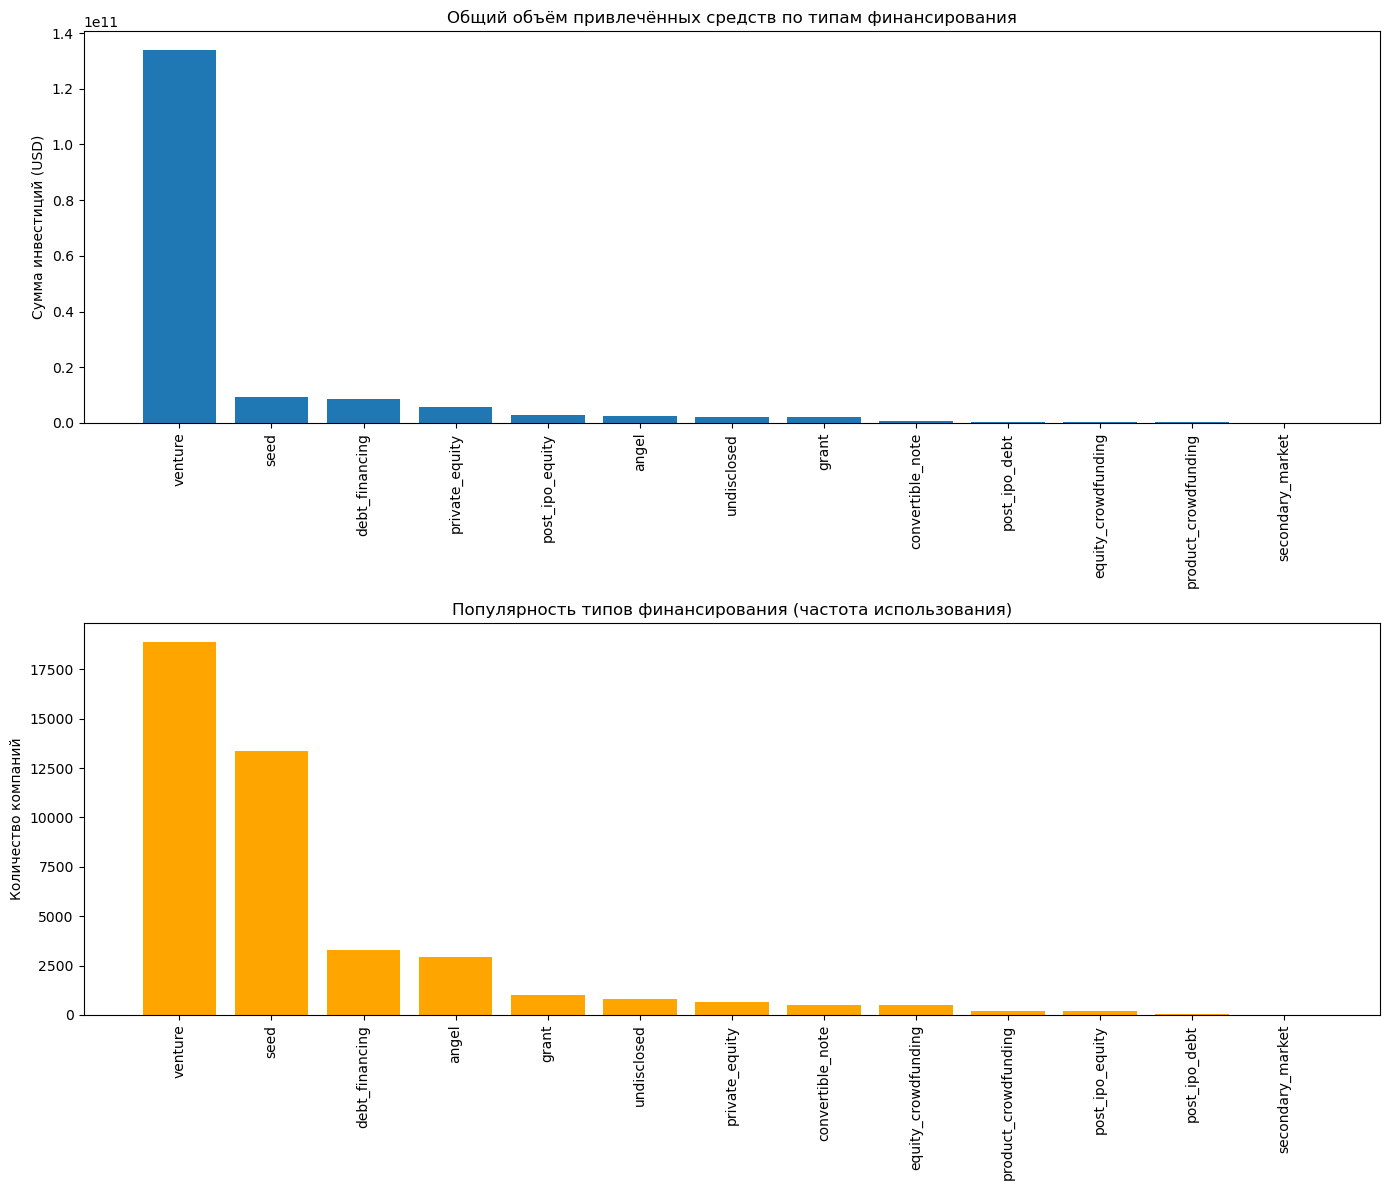

,Общий объём инвестиций,Количество компаний
venture,1.338789e+11,18882
seed,9.407984e+09,13354
debt_financing,8.530616e+09,3285
private_equity,5.853570e+09,648
post_ipo_equity,2.806170e+09,175
angel,2.536151e+09,2937
undisclosed,2.324482e+09,821
grant,1.992364e+09,1003
convertible_note,5.643104e+08,520
post_ipo_debt,3.117183e+08,28


In [48]:
# Типы финансирования, которые анализируем
funding_types = [
    'seed', 'venture', 'equity_crowdfunding', 'undisclosed', 'convertible_note',
    'debt_financing', 'angel', 'grant', 'private_equity', 'post_ipo_equity',
    'post_ipo_debt', 'secondary_market', 'product_crowdfunding'
]

# Общий объём финансирования по типу
funding_sums = df[funding_types].sum().sort_values(ascending=False)

# Частота использования каждого типа (сколько раз встречается > 0)
funding_counts = (df[funding_types] > 0).sum().sort_values(ascending=False)

# Два графика
fig, axes = plt.subplots(2, 1, figsize=(14, 12))

# Общие суммы 
axes[0].bar(funding_sums.index, funding_sums.values)
axes[0].set_title('Общий объём привлечённых средств по типам финансирования')
axes[0].set_ylabel('Сумма инвестиций (USD)')
axes[0].tick_params(axis='x', rotation=90)

# Популярность
axes[1].bar(funding_counts.index, funding_counts.values, color='orange')
axes[1].set_title('Популярность типов финансирования (частота использования)')
axes[1].set_ylabel('Количество компаний')
axes[1].tick_params(axis='x', rotation=90)

plt.tight_layout()
plt.show()

# Таблица сравнения 
comparison = (
    pd.DataFrame({
        'Общий объём инвестиций': funding_sums,
        'Количество компаний': funding_counts
    })
    .sort_values('Общий объём инвестиций', ascending=False)
)

display(comparison)


**Вывод по типам финансирования**

- По графикам видно, что **venture** значительно выделяется по объёму вложенных средств — этот тип финансирования привлекает больше всего денег. **Seed** и **debt_financing** занимают следующие позиции, но их объёмы заметно меньше. Остальные типы финансирования либо широко используются, но с невысокими суммами, либо встречаются редко и приносят сравнительно небольшие инвестиции.


- Стоит обратить внимание на **venture**, так как этот сегмент концентрирует основную часть вложений. Для более диверсифицированной стратегии можно рассматривать **seed** и **debt_financing**, которые часто используются компаниями и дают стабильный поток сделок. Остальные типы финансирования больше подходят для нишевых вложений или экспериментов с новыми моделями.


- Построим график суммарных объёмов возвратов от разных типов финансирования за весь период на основе дополнительного датасета.

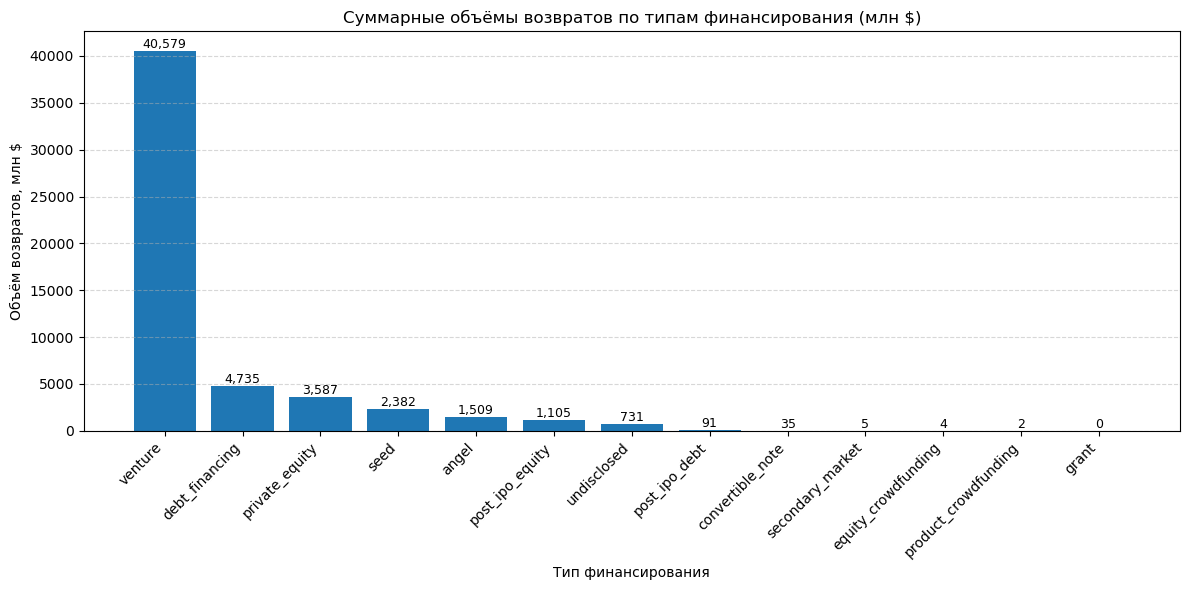

In [49]:
# Выбираем числовые столбцы, исключая 'year' 
numeric_cols = [c for c in cb_returns.columns 
                if c != 'year']


# Суммарные возвраты по типам
returns_sum = cb_returns[numeric_cols].sum(skipna=True).sort_values(ascending=False)

# Построим график
plt.figure(figsize=(12,6))
bars = plt.bar(returns_sum.index, returns_sum.values)

# Подписи над столбцами — красивые числа
for bar in bars: 
    h = bar.get_height() 
    plt.text(bar.get_x() + bar.get_width()/2, h, 
             f'{h:,.0f}', ha='center', va='bottom', 
fontsize=9, rotation=0)

plt.title('Суммарные объёмы возвратов по типам финансирования (млн $)')
plt.ylabel('Объём возвратов, млн $')
plt.xlabel('Тип финансирования')
plt.xticks(rotation=45, ha='right')
plt.grid(axis='y', linestyle='--', alpha=0.5)
plt.tight_layout()
plt.show()


**Вывод:**

- **Venture** явно лидирует по суммарным возвратам — почти в 9 раз больше, чем следующий тип финансирования (debt_financing). Это подтверждает, что венчурные инвестиции приносят наибольший возврат средств инвесторам.

- **Debt financing, private equity и seed** занимают следующие места — они стабильные и дают значимый, но гораздо меньший возврат по сравнению с венчурными инвестициями.

- Остальные типы финансирования, включая **angel, post_ipo_equity и undisclosed**, дают умеренные возвраты, но уже на порядок меньше лидера.

- Наименее значимые возвраты наблюдаются у остальных типав финансирования — они почти не влияют на суммарный объём возвратов.

- У **grant** возвраты отсутвуют — это закономерно, поскольку грантовое финансирование изначально не предполагает возврат вложенных средств. Это нерыночный механизм поддержки проектов, а не инвестиционный инструмент.

Основное внимание стоит уделять венчурным инвестициям, так как именно они формируют основную долю возврата. Более стабильные, но менее доходные варианты, такие как debt financing или private equity, подходят для диверсификации и снижения рисков.

## Шаг 4. Анализ динамики

### 4.1 Динамика предоставления финансирования по годам

- Рассчитаем для каждой компании средний объём одного раунда финансирования на основе столбцов `funding_total_usd` и `funding_rounds`.
- Построим два графика: первый покажет, как менялся типичный размер инвестиций за один раунд с годами, а второй — динамику общего количества раундов финансирования по годам, отражая активность рынка. На основе этих графиков определим, в каком году размер одного раунда был максимальным и какова была ситуация в 2014 году.


,name,funding_total_usd,funding_rounds,avg_funding_per_round
1,University of New Brunswick,2000000.0,1.0,2.000000e+06
2,DuPont,9000000.0,1.0,9.000000e+06
3,University of Michigan,7700000.0,3.0,2.566667e+06
4,Case Western Reserve University,540000.0,1.0,5.400000e+05
7,Duke University,8700000.0,1.0,8.700000e+06
9,WeGame,3500000.0,2.0,1.750000e+06
11,Mayne Pharma,2705000.0,1.0,2.705000e+06
12,Siemens,8900000.0,1.0,8.900000e+06
16,Michigan State University,3900000.0,1.0,3.900000e+06
18,Wilberforce University,2000000.0,1.0,2.000000e+06


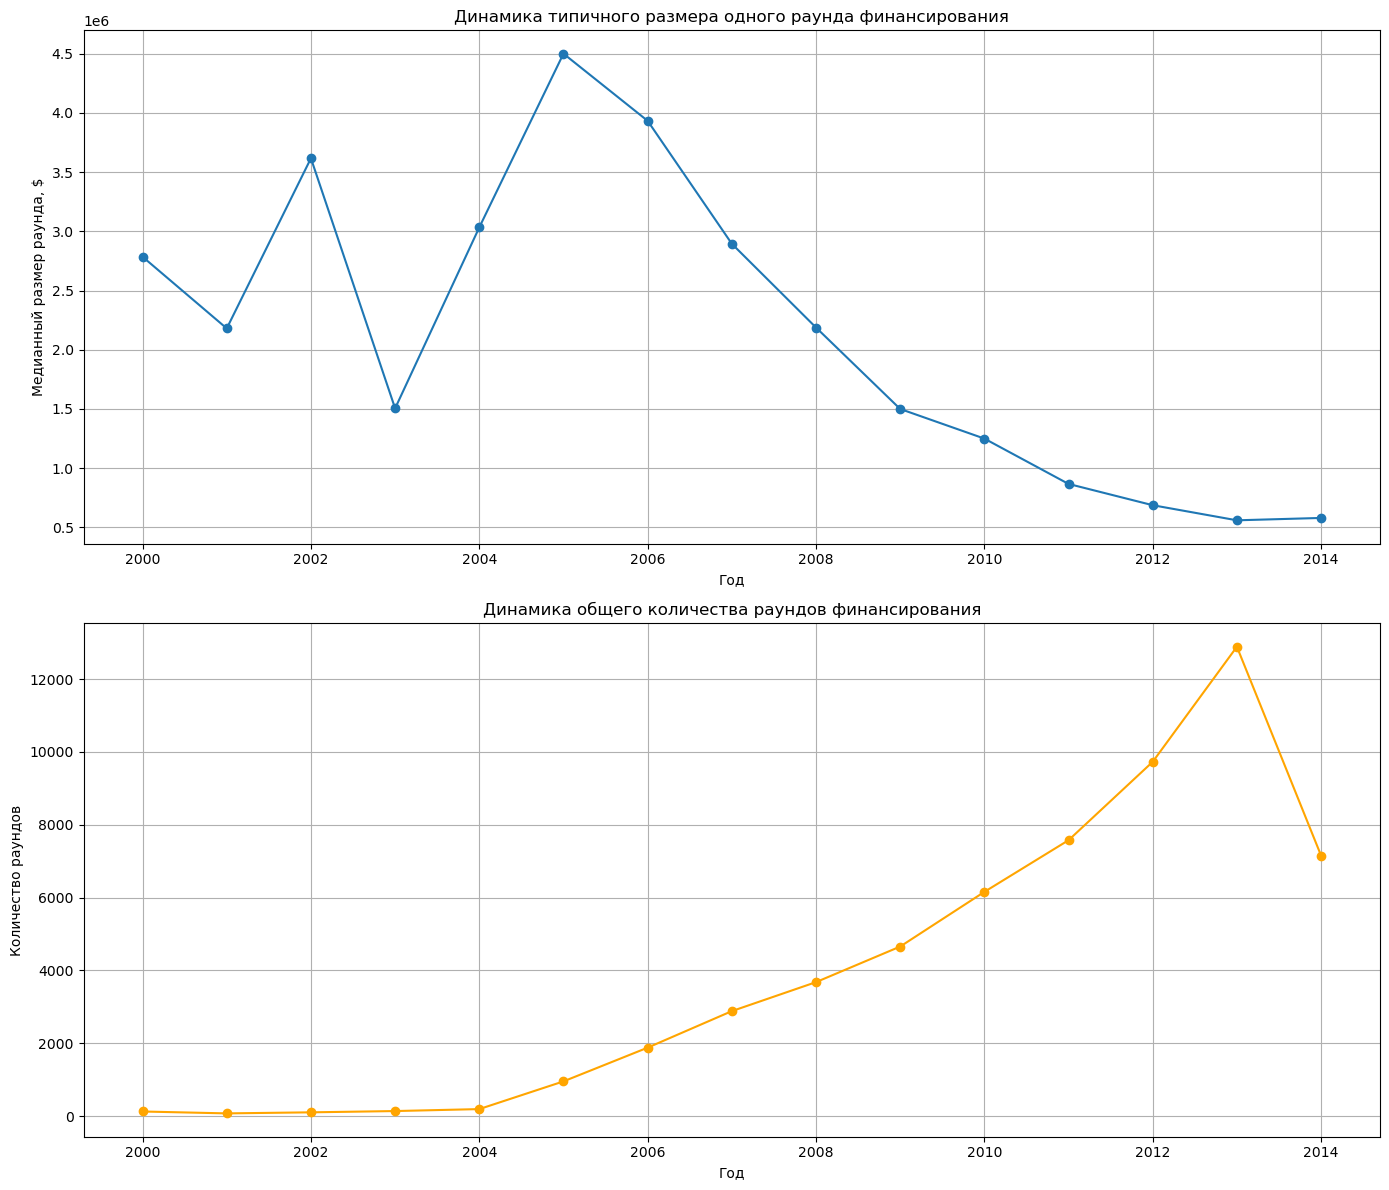

,year,avg_round_size,total_rounds
0,2000,2.785000e+06,126.0
1,2001,2.180175e+06,74.0
2,2002,3.616667e+06,103.0
3,2003,1.505000e+06,138.0
4,2004,3.033333e+06,192.0
5,2005,4.500000e+06,953.0
6,2006,3.932850e+06,1879.0
7,2007,2.894820e+06,2882.0
8,2008,2.187798e+06,3678.0
9,2009,1.500000e+06,4655.0


In [50]:
# Рассчитываем средний объём одного раунда для каждой компании
df['avg_funding_per_round'] = df['funding_total_usd'] / df['funding_rounds']

# Выводим таблицу с интересующими столбцами
company_rounds_table = df[['name', 'funding_total_usd', 'funding_rounds', 'avg_funding_per_round']]
display(company_rounds_table.head(10))

# Группировка по годам (берём медианный размер раунда и общее количество раундов)
yearly_stats = df.groupby(df['mid_funding_at'].dt.year).agg(
    avg_round_size=('avg_funding_per_round', 'median'),
    total_rounds=('funding_rounds', 'sum')
).reset_index().rename(columns={'mid_funding_at': 'year'})

# Два графика рядом
fig, axes = plt.subplots(2, 1, figsize=(14, 12))

# График 1 — динамика типичного размера раунда
axes[0].plot(yearly_stats['year'], yearly_stats['avg_round_size'], marker='o')
axes[0].set_title('Динамика типичного размера одного раунда финансирования')
axes[0].set_xlabel('Год')
axes[0].set_ylabel('Медианный размер раунда, $')
axes[0].grid(True)

# График 2 — динамика количества раундов
axes[1].plot(yearly_stats['year'], yearly_stats['total_rounds'], marker='o', color='orange')
axes[1].set_title('Динамика общего количества раундов финансирования')
axes[1].set_xlabel('Год')
axes[1].set_ylabel('Количество раундов')
axes[1].grid(True)

plt.tight_layout()
plt.show()

# Создаём таблицу, чтобы скинуть мне результаты для вывода
yearly_stats_for_output = yearly_stats.copy()
display(yearly_stats_for_output)


**Анализ динамики раундов финансирования и средних сумм по годам:**

**Максимальный средний размер раунда:** самый крупный типичный раунд был зафиксирован в 2005 году — около 4,5 млн USD. Это говорит о том, что в этот год стартапы привлекали относительно крупные суммы на один раунд.

**Особенности 2014 года:**

  * Количество раундов: меньше, чем в предыдущие годы, что указывает на снижение активности рынка.
  * Средний размер раунда: фактически не изменился по сравнению с предыдущим годом, что показывает стабильность типичных сумм на один раунд.

**Вывод:** в 2014 году наблюдалась снижение числа сделок при практически неизменном типичном размере раунда, то есть рынок был менее активным, но отдельные стартапы продолжали привлекать стандартные суммы инвестиций.


### 4.2 Динамика размера общего финансирования по массовым сегментам рынка для растущих в 2014 году сегментов

- Составим сводную таблицу суммарного финансирования (`funding_total_usd`) по сегментам рынка и годам, затем отберём только массовые сегменты, которые показали рост в 2014 году по сравнению с 2013.
- Построим график изменения суммарного финансирования по годам для этих сегментов, чтобы наглядно увидеть, какие сегменты демонстрируют наиболее быстрый и устойчивый рост.


In [51]:
# Оставляем только массовые сегменты
df_mass = df[~df['market'].isin(['mid', 'niche', 'unknown'])].copy()

# Группируем по году и сегменту
pivot_funding = df_mass.pivot_table(
    index=df_mass['mid_funding_at'].dt.year,
    columns='market',
    values='funding_total_usd',
    aggfunc='sum'
).fillna(0)

display(pivot_funding)
print("Количество столбцов:", pivot_funding.shape[1])


market,3d,3d_printing,ad_targeting,advertising,advertising_networks,advertising_platforms,aerospace,agriculture,algorithms,alternative_medicine,analytics,android,animal_feed,app_marketing,application_platforms,apps,archiving,art,artificial_intelligence,assisitive_technology,audio,augmented_reality,automotive,b2b,banking,batteries,beauty,bicycles,big_data,big_data_analytics,biotechnology,bitcoin,blogging_platforms,brand_marketing,brewing,broadcasting,business_analytics,business_development,business_intelligence,business_productivity,business_services,cad,career_management,cars,charity,chat,chemicals,civil_engineers,classifieds,clean_energy,clean_technology,clinical_trials,cloud_computing,cloud_data_services,cloud_infrastructure,cloud_management,coffee,collaboration,collaborative_consumption,colleges,comics,commercial_real_estate,communications_infrastructure,communities,computer_vision,computers,construction,consulting,consumer_electronics,consumer_goods,consumer_internet,consumers,contact_management,content,content_creators,content_delivery,content_discovery,content_syndication,cooking,corporate_training,cosmetics,coupons,craft_beer,credit,crm,crowdfunding,crowdsourcing,curated_web,customer_service,cyber_security,data_center_automation,data_centers,data_mining,data_security,databases,defense,dental,design,designers,developer_apis,developer_tools,development_platforms,diagnostics,digital_entertainment,digital_media,discounts,distribution,distributors,domains,e-commerce,e-commerce_platforms,education,educational_games,electronics,email,email_marketing,embedded_hardware_and_software,employment,energy,energy_efficiency,energy_it,energy_management,enterprise_resource_planning,enterprise_security,enterprise_software,enterprises,entertainment,entertainment_industry,entrepreneur,environmental_innovation,event_management,events,exercise,face_recognition,facebook_applications,families,farming,fashion,film,finance,finance_technology,financial_services,fitness,flash_storage,fleet_management,food_processing,forums,fraud_detection,freelancers,gadget,gambling,game,games,gamification,general_public_worldwide,gift_card,gold,government_innovation,governments,gps,hardware,hardware_+_software,health_and_wellness,health_care,health_care_information_technology,health_services_industry,healthcare_services,high_tech,home_&_garden,home_automation,home_renovation,hospitality,hospitals,human_computer_interaction,human_resources,identity,identity_management,image_recognition,incubators,information_security,information_services,information_technology,infrastructure,innovation_management,insurance,intelligent_systems,interface_design,interior_design,internet,internet_marketing,internet_of_things,internet_radio_market,investment_management,ios,ipad,iphone,it_management,jewelry,kids,language_learning,law_enforcement,legal,licensing,lifestyle,lifestyle_products,lighting,linux,local,local_based_services,local_businesses,local_search,location_based_services,logistics,logistics_company,loyalty_programs,machine_learning,manufacturing,maps,market_research,marketing_automation,marketplaces,material_science,mechanical_solutions,media,medical,medical_devices,medical_marijuana_patients,medical_professionals,messaging,mhealth,minerals,mining_technologies,mobile,mobile_advertising,mobile_commerce,mobile_devices,mobile_games,mobile_health,mobile_payments,mobile_security,mobile_software_tools,music,music_services,music_venues,musicians,nanotechnology,natural_gas_uses,natural_language_processing,natural_resources,navigation,network_security,networking,news,nightlife,non_profit,nonprofits,nutrition,oil_&_gas,oil_and_gas,online_dating,online_gaming,online_rental,online_reservations,online_scheduling,online_shopping,online_travel,online_video_advertising,open_source,organic_food,outsourcing,p2p_money_transfer,parenting,parking,payments,peer-to-peer,personal_finance,personalization,pets,pharmaceuticals,photo_sharing,photography,physical_security,point_of_sale,politics,portals,

Количество столбцов: 394


In [52]:
# Отбираем сегменты, которые выросли в 2014 году по сравнению с 2013
if 2013 in pivot_funding.index and 2014 in pivot_funding.index:
    growth_segments = pivot_funding.loc[2014] > pivot_funding.loc[2013]
    pivot_funding = pivot_funding.loc[:, growth_segments]

# Проверим пробразование
print("Количество столбцов:", pivot_funding.shape[1])

Количество столбцов: 220


- Построим график, поделив на две группы для лучшей читаемости:

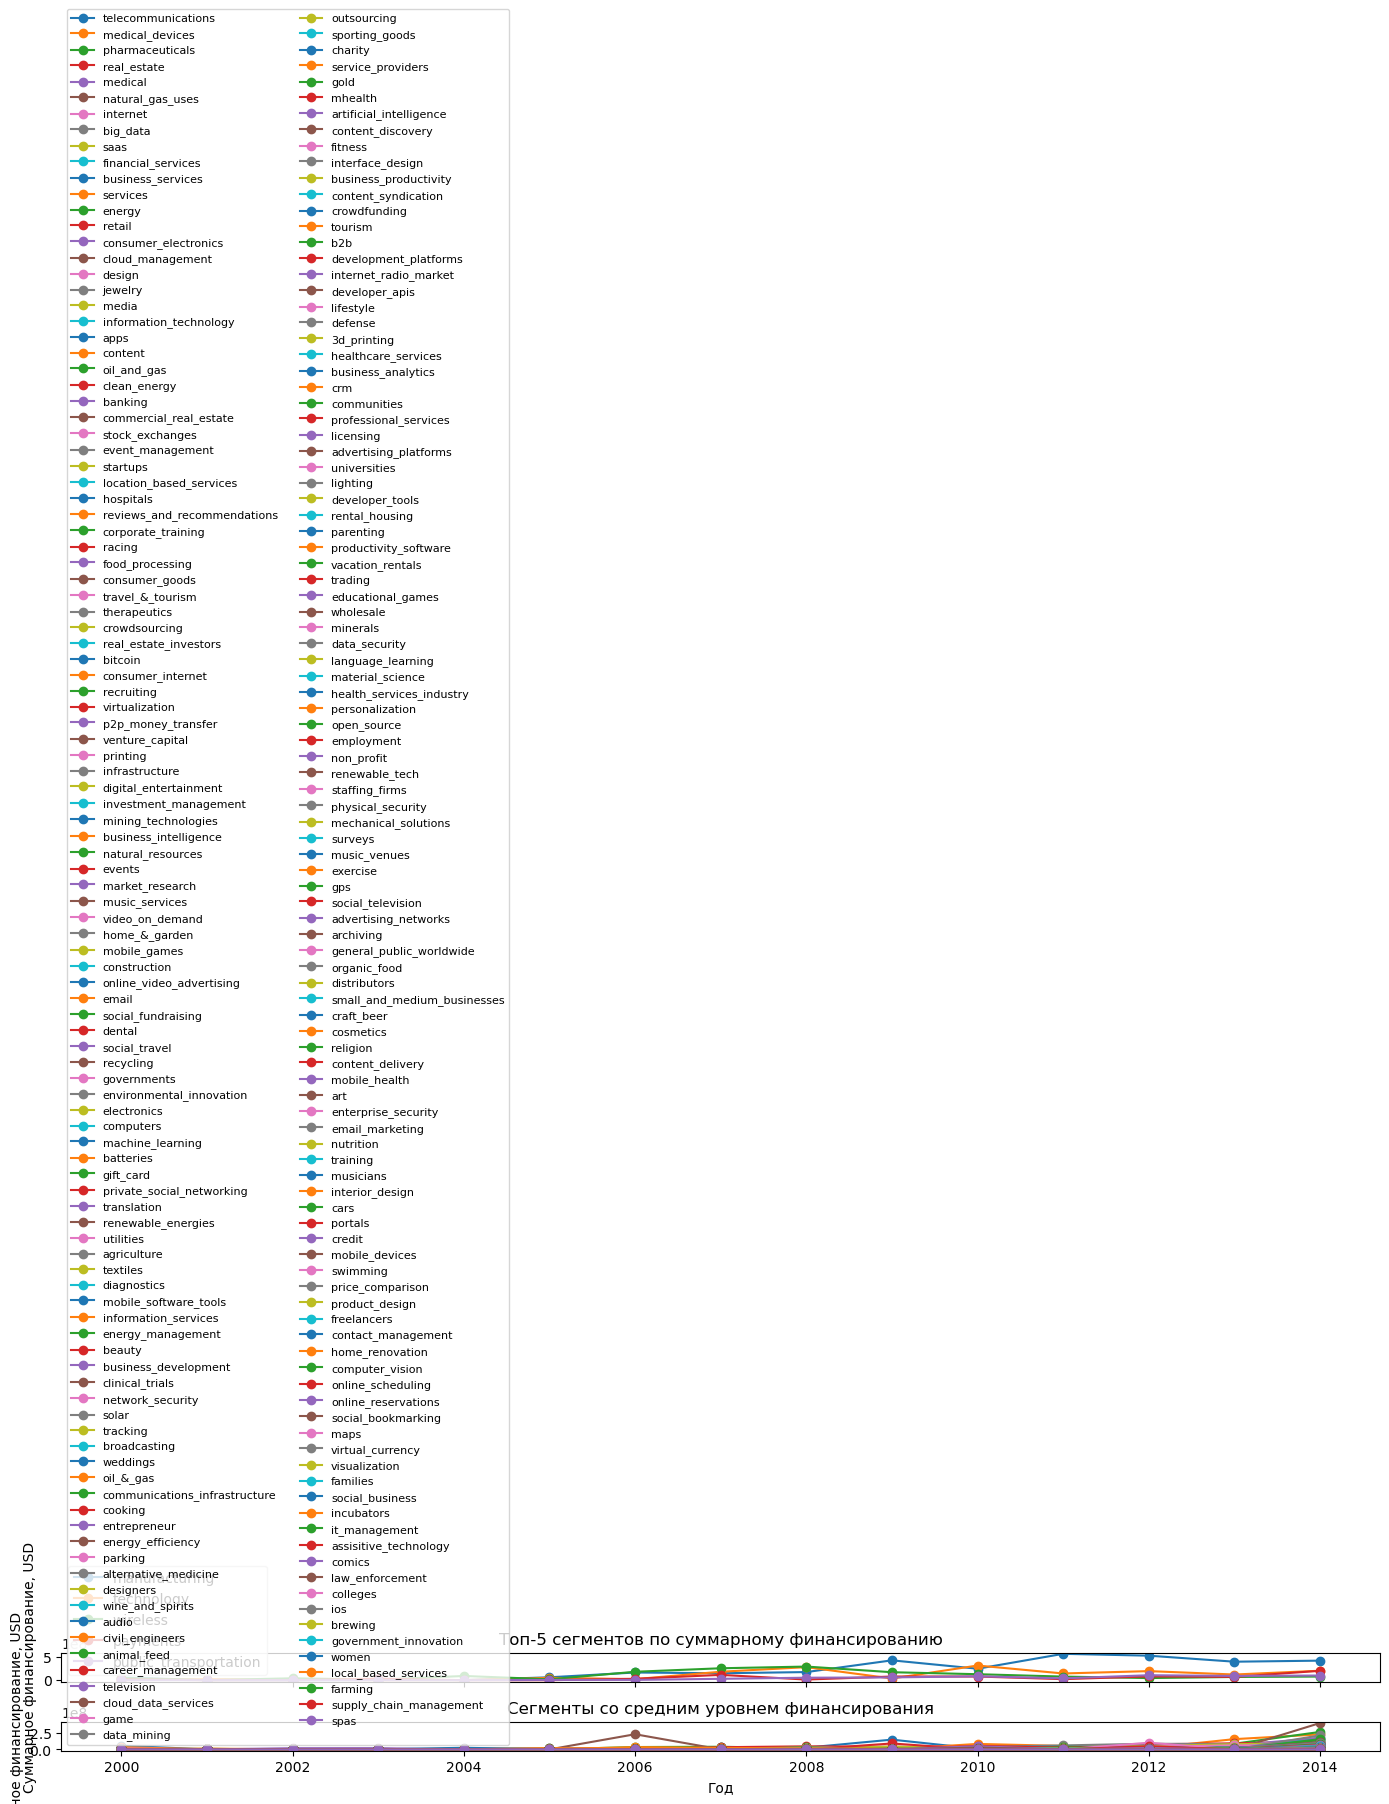

In [53]:
# Считаем суммарное финансирование по сегментам и сортируем
total_funding = pivot_funding.sum().sort_values(ascending=False)

# Разделяем на 2 группы
top_segments = total_funding.head(5).index
low_segments = total_funding[5:].index

fig, axes = plt.subplots(2, 1, figsize=(14, 14), sharex=True)

# Топ-5 сегментов
for seg in top_segments:
    axes[0].plot(pivot_funding.index, pivot_funding[seg], marker='o', label=seg)
axes[0].set_title('Топ-5 сегментов по суммарному финансированию')
axes[0].set_ylabel('Суммарное финансирование, USD')
axes[0].legend()

# Остальные 5 сегментов
for seg in low_segments:
    axes[1].plot(pivot_funding.index, pivot_funding[seg], marker='o', label=seg)
axes[1].set_title('Сегменты со средним уровнем финансирования')
axes[1].set_xlabel('Год')
axes[1].set_ylabel('Суммарное финансирование, USD')
axes[1].legend(ncol=2, fontsize=8)


plt.tight_layout()
plt.show()



**Вывод:**

* С 2008 года рынок финансирования демонстрирует значительные изменения. Наиболее быстрый рост в 2014 году показывают сегменты **apps**, **internet**, **saas** и **medical** — здесь суммы инвестиций увеличиваются быстрее, чем в других сегментах, что говорит о высокой инвестиционной активности и возможности для прибыльных вложений.

* Сегменты **real_estate**, **technology**, **manufacturing** и **design** продолжают демонстрировать стабильный рост по объёму финансирования, хотя темп прироста ниже, чем у быстрорастущих сегментов. Эти направления остаются ключевыми для крупных вложений.

* Остальные сегменты растут медленнее, но всё равно показывают положительную динамику, что делает их интересными для диверсификации инвестиционного портфеля или тестирования новых идей.

* Стоит концентрироваться на быстрорастущих сегментах (**apps**, **internet**, **saas**, **medical**) для активного поиска возможностей, а стабильные сегменты (**technology**, **manufacturing**, **real_estate**, **design**) использовать для крупных и более безопасных вложений.


### 4.3 Годовая динамика доли возвращённых средств по типам финансирования

- Проведем анализ эффективности различных типов финансирования: для каждого года рассчитаем долю возвращённых средств от вложенных (нормированные возвраты) и одновременно обработаем аномальные значения, чтобы избежать искажений из-за выбросов.


In [54]:
# Создаем копии данных
df_copy = df.copy()
cb_returns_copy = cb_returns.copy()

# Типы финансирования
fin_type = [
    'seed', 'venture', 'equity_crowdfunding', 'undisclosed', 'convertible_note',
    'debt_financing', 'angel', 'private_equity', 'post_ipo_equity',
    'post_ipo_debt', 'secondary_market', 'product_crowdfunding'
]

# Агрегируем привлеченные средства по годам 
df_copy['year'] = df_copy['mid_funding_at'].dt.year
f_year = df_copy.groupby('year')[fin_type].sum(min_count=1)

# Подготавливаем возвраты
if 'year' in cb_returns_copy.columns:
    r_year = cb_returns_copy.set_index('year')[fin_type]
else:
    if cb_returns_copy.index.name != 'year':
        cb_returns_copy.index.name = 'year'
    r_year = cb_returns_copy[fin_type]

# Приводим возвраты 
r_year = r_year * 1e6

# Выравниваем годы
years = sorted(set(f_year.index).union(r_year.index))
f_year = f_year.reindex(years)
r_year = r_year.reindex(years)

# Нормированная доля возврата: returns / funding
eps = 1e-60
ratio = r_year / (f_year + eps)

# Очистка аномалий
def iqr_mask(s: pd.Series):
    q1, q3 = s.quantile([0.25, 0.75])
    iqr = q3 - q1
    lo, hi = q1 - 1.5 * iqr, q3 + 1.5 * iqr
    return s.where(s.between(lo, hi))

ratio_clean = ratio.apply(iqr_mask)
ratio_table = ratio_clean.copy()
display(ratio_table.head(15))


,seed,venture,equity_crowdfunding,undisclosed,convertible_note,debt_financing,angel,private_equity,post_ipo_equity,post_ipo_debt,secondary_market,product_crowdfunding
year,,,,,,,,,,,,
2000,1.059702,0.148541,0.000000,0.328334,0.000000e+00,0.618571,0.266956,0.000000,2.710694e-01,0.000000,2.591054e-02,0.000000
2001,1.079592,0.083440,0.000000,0.379880,6.666667e-03,0.349982,1.180000,0.000000,4.600000e+65,0.000000,4.600000e+65,0.000000
2002,0.629707,0.602450,0.000000,0.608878,NaN,0.223388,1.136667,0.201333,1.133333e+00,0.000000,6.000000e+64,0.000000
2003,0.464632,0.620103,0.000000,NaN,1.000000e+64,1.038095,0.095028,NaN,NaN,0.000000,8.000000e+64,0.000000
2004,0.548476,0.717382,0.000000,0.527559,1.000000e+64,0.439698,0.833504,0.087600,NaN,0.000000,5.500000e+65,0.000000
2005,0.674695,0.542768,0.000000,0.525652,NaN,0.344964,0.584223,0.080000,7.318565e-01,0.000000,5.000000e+64,0.000000
2006,0.939265,0.324350,0.203632,0.759438,1.663181e-01,0.792519,0.717008,0.935453,NaN,0.000000,1.200000e+65,0.000000
2007,0.370976,0.285530,NaN,0.405654,2.280972e-01,0.537414,0.817837,0.315634,2.030000e+00,0.000000,5.700000e+65,0.000000
2008,0.297744,0.186434,NaN,0.342060,5.978832e-02,0.853341,0.412476,0.679925,2.341111e+00,0.000000,4.700000e+65,0.000000


- Построим график, на котором отобразим нормированные значения возврата средств для типов финансирования `venture`, `debt_financing`, `private_equity`, `seed` и `angel`.

In [55]:
# Итоговая таблица для выбранных типов
pro_types = ['venture', 'debt_financing', 'private_equity', 'seed', 'angel']
pro_cols = [c for c in pro_types if c in ratio_clean.columns]

print("Нормированные возвраты по типам финансирования:")
ratio_clean[pro_cols].round(4)

Нормированные возвраты по типам финансирования:


,venture,debt_financing,private_equity,seed,angel
year,,,,,
2000,0.1485,0.6186,0.0000,1.0597,0.2670
2001,0.0834,0.3500,0.0000,1.0796,1.1800
2002,0.6024,0.2234,0.2013,0.6297,1.1367
2003,0.6201,1.0381,NaN,0.4646,0.0950
2004,0.7174,0.4397,0.0876,0.5485,0.8335
2005,0.5428,0.3450,0.0800,0.6747,0.5842
2006,0.3244,0.7925,0.9355,0.9393,0.7170
2007,0.2855,0.5374,0.3156,0.3710,0.8178
2008,0.1864,0.8533,0.6799,0.2977,0.4125


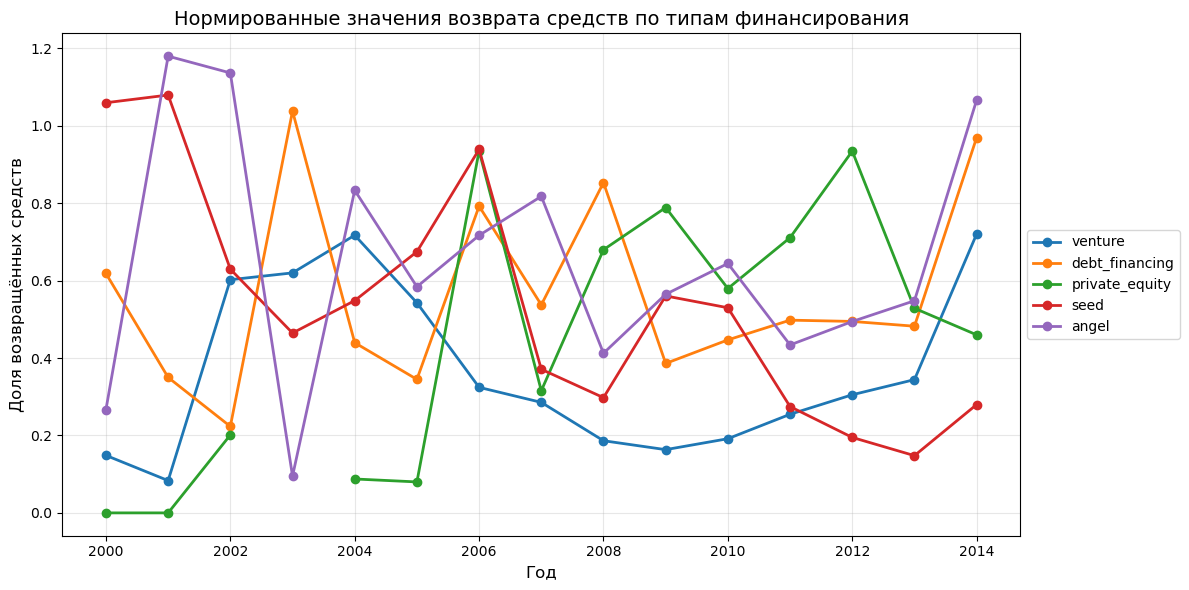

In [56]:
# График по выбранным типам финансирования
plt.figure(figsize=(12, 6))

# Цветовая палитра
colors = sns.color_palette("tab10", n_colors=len(pro_cols))

for i, col in enumerate(pro_cols):
    plt.plot(
        ratio_clean.index,
        ratio_clean[col],
        marker='o',
        linewidth=2,
        markersize=6,
        label=col,
        color=colors[i]
    )

plt.title('Нормированные значения возврата средств по типам финансирования', fontsize=14)
plt.xlabel('Год', fontsize=12)
plt.ylabel('Доля возвращённых средств', fontsize=12)
plt.legend(loc='center left', bbox_to_anchor=(1, 0.5))
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

- Сглаживаем значения, например, окном в 3 года:

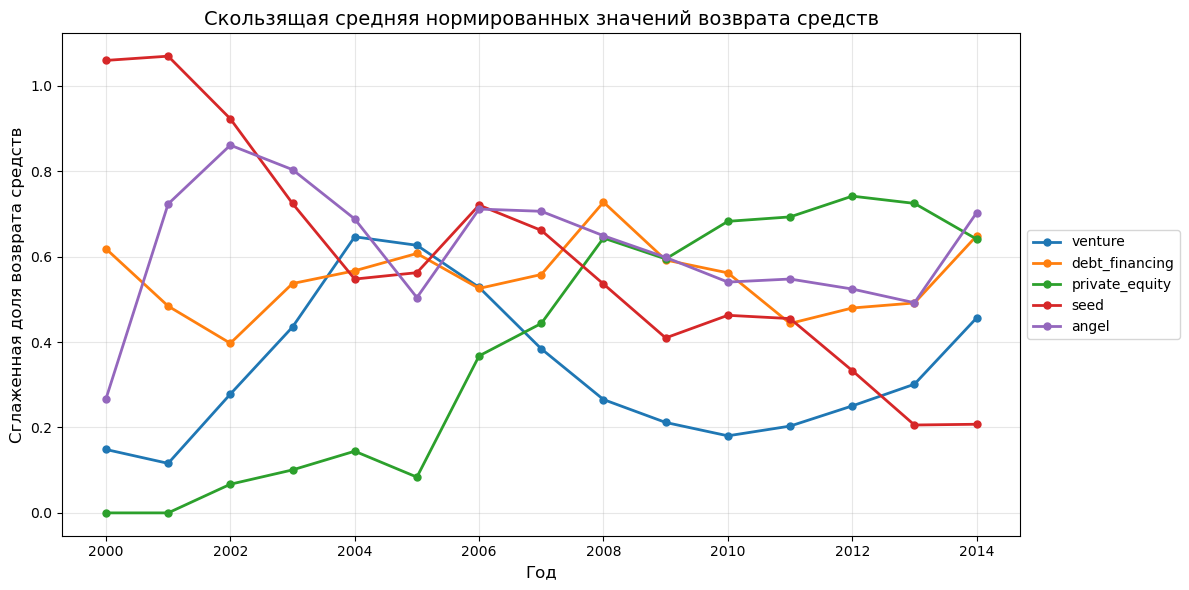

In [57]:
# Сглаживание скользящей средней
ratio_smooth = ratio_clean.rolling(window=3, min_periods=1).mean()

plt.figure(figsize=(12, 6))
colors = sns.color_palette("tab10", n_colors=len(pro_cols))

for i, col in enumerate(pro_cols):
    plt.plot(
        ratio_smooth.index,
        ratio_smooth[col],
        marker='o',
        linewidth=2,
        markersize=5,
        label=col,
        color=colors[i]
    )

plt.title('Скользящая средняя нормированных значений возврата средств', fontsize=14)
plt.xlabel('Год', fontsize=12)
plt.ylabel('Сглаженная доля возврата средств', fontsize=12)
plt.legend(loc='center left', bbox_to_anchor=(1, 0.5))
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()


После визуального анализа по годам:

- **Venture**: значительная нестабильность. Есть периоды роста (2002–2004, 2014), но также сильное падение (2008–2011). Волатильность высокая.  
- **Debt financing**: тенденция ближе к устойчивому росту. Несмотря на спады (2002, 2004–2005), начиная с 2006 наблюдается повышение, особенно сильный рост к 2014 году.  
- **Private equity**: сравнительно стабильная положительная динамика с 2006 года, без резких обвалов. Рост к 2014 году впечатляющий.  
- **Seed**: нестабильные значения, резкие колебания и постепенный спад после 2006 года. Этот тренд не обязательно отражает реальное падение эффективности. Он может быть связан с эффектом незавершённости когорт (поздние годы ещё не дали возврат) и природной волатильностью ранних стадий. 
- **Angel**: выглядит стабильно до 2006 года, но затем колебания без выраженного тренда, несмотря на рост в 2014 году.

**Вывод:**

Наиболее устойчивый рост показателя нормированного возврата средств наблюдается у **Private equity** и **Debt financing**.  

- **Private equity** демонстрирует последовательное укрепление после 2005 года и минимальные резкие колебания.  
- **Debt financing** также показывает нарастающий тренд с заметным улучшением к последним годам наблюдения.



## Шаг 5. Итоговый вывод и рекомендации

В 2015 году, на основании анализа предоставленных данных по рынку стартапов и механизмам финансирования, можно сформулировать обоснованные рекомендации для инвестора и подвести итог реализации проекта.

### **Рекомендация по выбору отрасли для инвестиций:**

- Оптимальным направлением инвестирования являются быстрорастущие технологические отрасли: **apps, internet, saas, medical**. Эти сегменты демонстрировали самый высокий темп роста суммарного финансирования в 2014 году, стабильную положительную динамику и приток инвестиционных ресурсов.
- Для крупных и стабильных вложений следует также рассматривать массовые сегменты, такие как **software, cloud computing, enterprise software, biotechnology, health care, e-commerce**. Здесь наблюдается сильная концентрация компаний и инвестиционных потоков, что соответствует зрелости рынка и устойчивому спросу.
- Реализация диверсифицированной стратегии эффективна за счет включения в портфель стабильных, но менее динамично растущих сегментов: **technology, manufacturing, real estate, design**. В них сохраняется положительная динамика, хотя темпы прироста ниже — такие вложения подходят для снижения рисков и стабильного долгосрочного дохода.

### **Рекомендация по типу финансирования:**

- **Venture финансирование** является наиболее эффективным инструментом для отраслей с быстрым ростом и высокой волатильностью — именно этот тип инвестиций в технологических сегментах обеспечивает максимальный объём вложенных средств и лидирует по суммарному возврату капитала.
- Для тех, кто предпочитает более устойчивый и менее рисковый профиль инвестиций, рекомендуется рассматривать **private equity** и **debt financing**. Они показывают стабильный долгосрочный рост возвратов, небольшие колебания и оптимальны для крупных, зрелых компаний или проектов среднего риска.
- Seed и angel финансирование активно используются, однако характеризуются меньшими объёмами и высокой нестабильностью возврата средств. Это актуально только для рынка на ранних стадиях или нишевых направлений.

### **Итоги проекта:**

**Последовательность шагов:**

- Выполнена загрузка, предварительная очистка и предобработка данных; проведён анализ соответствия исходных данных описанию и выявление пропусков.
- Проведён инжиниринг признаков: категоризация компаний по срокам финансирования, анализ распределения типов рынков, унификация нишевых и средних категорий.
- Выявлены выбросы и аномалии в финансировании, проведён структурный анализ капиталоёмкости сегментов.
- Проанализирован временной профиль активности рынка, динамика объёмов и раундов финансирования по годам и сегментам.
- Сравнены типы финансирования по суммам, популярности и возвратам; выявлены наилучшие и устойчивые инструменты.
- Оценена динамика возврата инвестиций, определены типы финансирования с максимальным ростом возвратов и наименьшей волатильностью.

**Ключевые выводы:**

- В технологических сегментах максимально проявлен инвестиционный потенциал — высокие темпы роста, стабильное расширение рынка и высокий возврат вложений.
- Venture финансирование доминирует по объёму и отдаче, что соответствует высоким ожиданиям инвесторов в быстрорастущих областях.
- Private equity и debt financing показали наименьшую волатильность и устойчивый тренд возвратов, что делает их оптимальными для долгосрочного и структурного инвестирования.
- Значительная часть компаний получает только один раунд финансирования, однако основной объём ресурсов сконцентрирован у тех, кто финансируется в течение нескольких лет.

**Согласованность выводов:**

- Выводы по отраслям и типам финансирования хорошо согласуются: перспективные сегменты рынка совпадают с предпочтительными типами финансирования, а рост инвестиций ведёт к увеличению возвратов для инвесторов.
- Имеются отдельные зоны сомнений — нестабильность seed и angel финансирования, а также высокая концентрация средств в ограниченном количестве сегментов. Это требует более осторожного подхода при диверсификации портфеля или работы с нишевыми рынками.
- Общая стратегия инвестирования на 2015 год должна строиться на выборе быстрорастущих технологических отраслей с акцентом на venture капитал, с добавлением более стабильных инструментов для диверсификации рисков.

***

**Рекомендации и выводы полностью соответствуют обнаруженным тенденциям, однако требуют регулярного пересмотра по мере выхода новых данных об окружающей рыночной среде**.